# Romania 2001: all eleven plot-ready counties

This notebook combines the **seven previously plotted counties** (AB, CS, GL, TL, AR, SB, B) with the **four newly reconciled counties** (CT, PH, TM, CJ). It uses their saved, source-checked Ministry pages and the same visible descriptive settings. It makes **no web requests**.

Run **Cell 1** to review settings, **Cell 2** to inspect source counts, then set `RUN_ANALYSIS = True` in **Cell 3** when you choose to generate the aggregate figures. **Cell 4** shows each county first and a separate combined plot last. You can change viewing controls without rerunning the analysis.

The peer pool is the participating applicants from each originating gymnasium, not all eighth graders. Printed name and admission score are provisional linkage keys because the archival ID is masked. Galați retains one unresolved applicant outcome. The applicant-weighted combined plot pools the selected counties by applicant; changing county mix across peer bins can alter its shape. These are descriptive associations, not causal effects or a national 41-county result.

Two combined views are now available: **applicant-weighted** (each applicant has equal weight) and **equal-county** (each county with eligible applicants in a given own-score band and peer-score bin contributes one rate). A county absent from a cell is not assigned a zero rate. The plot labels show how many counties contribute to each point.

The **gymnasium-mean** option is the literal version of one bin per gymnasium: a school's average includes all its observed applicants, and all its eligible applicants inherit the same shared bin. Its colored own-score bands use pooled cutoffs across the selected counties. "Top one" means a program in the highest observed cutoff tier within its category; archived preferences do not reveal each student's first choice.

In [1]:
# CELL 1 — VISIBLE RESEARCH SETTINGS
# Nothing is downloaded or analyzed when you run this cell. It only locates and
# reloads the companion code so edits made while Cursor was open take effect.
from pathlib import Path
import importlib
import sys
from IPython.display import Image, Markdown, display

def find_analysis_root():
    for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        candidate = parent / "3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis"
        if candidate.is_dir():
            return candidate
        if parent.name == "education_analysis" and (parent / "code").is_dir():
            return parent
    raise FileNotFoundError("Open this notebook from inside the dissertation repository.")

ANALYSIS_ROOT = find_analysis_root()
CODE_DIR = ANALYSIS_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
import EDUCATION_20261003_romania_four_county_program_identity_gate as identity_reader
import EDUCATION_20261004_romania_four_county_pilot as shared_plot_code
import EDUCATION_20261009_romania_ct_ph_tm_cj_descriptive_pilot as new_county_pilot
importlib.reload(identity_reader)
importlib.reload(shared_plot_code)
importlib.reload(new_county_pilot)

# All eleven source-checked plotting counties; remove codes here for a subset.
# The final combined plot pools exactly the selected counties, by applicant.
COUNTIES = ("AB", "CS", "GL", "TL", "AR", "SB", "B", "CT", "PH", "TM", "CJ")

# Frozen primary definition: highest fully occupied program cutoff in each
# of six original categories. Top two is a planned, cumulative comparison.
# These refer to CUTOFF TIERS, not simply the two programs with highest scores.
TOP_TIERS = (1, 2)
REQUIRE_FULL_PROGRAMS = True
COMBINE_PROGRAM_CATEGORIES = False
INCLUDE_VOCATIONAL_IN_PRIMARY = True

# Separate denominator comparisons. They never change the program ranking.
COMPARE_EXCLUDING_AMBIGUOUS_EXACT_PROGRAMS = True
COMPARE_EXCLUDING_VOCATIONAL_DESTINATIONS = True
COMPARE_POOLED_SCORE_BANDS = True

# OWN examination-score percentiles: red top 10%, orange 75th–90th,
# gray 50th–75th, blue below 50th. Change to, e.g., (95, 80, 50)
# only if you deliberately want a different descriptive band definition.
AI_PERCENTILE_CUTS = (90, 75, 50)

# Plot resolution only. The CSVs show applicants and distinct gymnasiums
# in every cell so thin or single-school points are visible.
PEER_STRENGTH_BINS = 10
HERO_BINS = 16

settings = new_county_pilot.Settings(
    counties=COUNTIES,
    top_tiers=TOP_TIERS,
    require_full_programs=REQUIRE_FULL_PROGRAMS,
    combine_program_categories=COMBINE_PROGRAM_CATEGORIES,
    include_vocational_in_primary=INCLUDE_VOCATIONAL_IN_PRIMARY,
    compare_excluding_ambiguous=COMPARE_EXCLUDING_AMBIGUOUS_EXACT_PROGRAMS,
    compare_excluding_vocational=COMPARE_EXCLUDING_VOCATIONAL_DESTINATIONS,
    compare_pooled_score_bands=COMPARE_POOLED_SCORE_BANDS,
    ai_percentile_cuts=AI_PERCENTILE_CUTS,
    peer_strength_bins=PEER_STRENGTH_BINS,
    hero_bins=HERO_BINS,
)
settings.validate()
print("Companion code:", new_county_pilot.__file__)
print("Counties:", COUNTIES, "| cutoff tiers:", TOP_TIERS)
print("Full programs:", REQUIRE_FULL_PROGRAMS, "| combine categories:", COMBINE_PROGRAM_CATEGORIES)
print("Own-score bands:", AI_PERCENTILE_CUTS, "| peer bins:", PEER_STRENGTH_BINS)
print("No download or outcome analysis has run.")

Companion code: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis/code/EDUCATION_20261009_romania_ct_ph_tm_cj_descriptive_pilot.py
Counties: ('AB', 'CS', 'GL', 'TL', 'AR', 'SB', 'B', 'CT', 'PH', 'TM', 'CJ') | cutoff tiers: (1, 2)
Full programs: True | combine categories: False
Own-score bands: (90, 75, 50) | peer bins: 10
No download or outcome analysis has run.


## Cell 2 — check the sources and movement counts

This rechecks all requested saved pages and shows name-free county counts before any plotting. It does not download data. Outgoing percentage divides by originating applicants; incoming percentage divides by destination placements. Students placed outside their origin county remain in the peer pool but are excluded from the local-program outcome denominator.

In [2]:
# CELL 2 — OFFLINE SOURCE PREVIEW; NO PLOTS OR DOWNLOADS
# This rereads and verifies the private pages. No personal rows are exported.
source_overview = new_county_pilot.source_preview(settings)
display(source_overview[[
    "county_name", "county", "directory_gymnasiums", "participating_gymnasiums",
    "gymnasiums_with_two_or_more_applicants", "origin_applicants",
    "origin_placed_locally", "outgoing_students", "origin_unassigned",
    "incoming_students", "outgoing_pct_of_origin_applicants",
    "incoming_pct_of_destination_placements",
]].rename(columns={
    "county_name": "County", "county": "Code",
    "directory_gymnasiums": "Gymnasiums in directory",
    "participating_gymnasiums": "Gymnasiums with applicants",
    "gymnasiums_with_two_or_more_applicants": "Gymnasiums with 2+ applicants",
    "origin_applicants": "Applicants", "origin_placed_locally": "Placed in home county",
    "outgoing_students": "Placed in another county", "origin_unassigned": "Unassigned",
    "incoming_students": "Admitted here from elsewhere",
    "outgoing_pct_of_origin_applicants": "Outgoing % of origin applicants",
    "incoming_pct_of_destination_placements": "Incoming % of destination placements",
}).round(2))
print("The requested counties passed their applicable source checks. Galați retains one unresolved applicant outcome.")

Checking the earlier 7 counties: AB, CS, GL, TL, AR, SB, B
Step 1/4 — verifying gymnasium and county source checkpoints...
VERIFIED AB: 168 gymnasium pages, 3041 applicant rows
VERIFIED CS: 171 gymnasium pages, 2606 applicant rows
VERIFIED GL: 190 gymnasium pages, 5345 applicant rows
VERIFIED TL: 103 gymnasium pages, 1953 applicant rows
VERIFIED AR: 136 gymnasium pages, 3164 applicant rows
VERIFIED SB: 152 gymnasium pages, 3236 applicant rows
VERIFIED B: 289 gymnasium pages, 22216 applicant rows
INDEXED 10/41 saved county report sets
INDEXED 20/41 saved county report sets
INDEXED 30/41 saved county report sets
INDEXED 40/41 saved county report sets
INDEXED 41/41 saved county report sets
  AB: 3,041 applicant rows; 85 programs; source counts agree
  CS: 2,606 applicant rows; 63 programs; source counts agree
  GL: 5,345 applicant rows; 74 programs; source counts agree
  TL: 1,953 applicant rows; 42 programs; source counts agree
2026-10-09 12:42:36 EDT | AR: RESOLVED 150 exact program ide

,County,Code,Gymnasiums in directory,Gymnasiums with applicants,Gymnasiums with 2+ applicants,Applicants,Placed in home county,Placed in another county,Unassigned,Admitted here from elsewhere,Outgoing % of origin applicants,Incoming % of destination placements
0,Alba,AB,168,161,149,3041,2958,77,6,19,2.53,0.64
1,Caraș-Severin,CS,171,143,133,2606,2318,142,146,15,5.45,0.64
2,Galați,GL,190,185,177,5345,5072,77,195,97,1.44,1.88
3,Tulcea,TL,103,91,85,1953,1787,148,18,7,7.58,0.39
4,Arad,AR,136,131,125,3164,2947,43,174,71,1.36,2.35
5,Sibiu,SB,152,144,133,3236,3158,41,37,118,1.27,3.60
6,Bucharest–Ilfov,B,289,275,269,22216,20652,53,1511,1317,0.24,5.99
7,Constanța,CT,185,180,169,6507,6213,43,251,123,0.66,1.94
8,Prahova,PH,259,253,244,6131,5879,52,200,82,0.85,1.38
9,Timiș,TM,202,196,189,5795,5561,15,219,213,0.26,3.69


The requested counties passed their applicable source checks. Galați retains one unresolved applicant outcome.


## Cell 3 — you start the analysis

Change `RUN_ANALYSIS` below to `True`, then run **this cell**. The companion saves name-free aggregate tables and PNGs in a timestamped output folder. It does not download anything. The full report explains the denominator, movement treatment, band boundaries, and interpretation limits. A repeat run creates a new folder, preserving prior results.

In [3]:
# CELL 3 — RESEARCHER-CONTROLLED DESCRIPTIVE RUN
RUN_ANALYSIS = True  # Change to True when you want the plots.

if not RUN_ANALYSIS:
    print("Analysis is off. Set RUN_ANALYSIS = True and rerun this cell.")
else:
    run_folder, summary = new_county_pilot.run_pilot(settings, run=True)
    print("Results saved:", run_folder)
    print("Read first:", run_folder / "report.md")
    display(summary[[
        "county", "tier", "source_applicants", "primary_denominator",
        "primary_successes", "primary_observed_success_fraction",
        "qualifying_programs", "qualifying_program_places",
    ]].rename(columns={
        "county": "County", "tier": "Top cutoff tiers",
        "source_applicants": "Applicants", "primary_denominator": "Outcome denominator",
        "primary_successes": "Selected", "primary_observed_success_fraction": "Observed fraction",
        "qualifying_programs": "Winning programs",
        "qualifying_program_places": "Places in winning programs",
    }))

Checking the earlier 7 counties: AB, CS, GL, TL, AR, SB, B
Step 1/4 — verifying gymnasium and county source checkpoints...
VERIFIED AB: 168 gymnasium pages, 3041 applicant rows
VERIFIED CS: 171 gymnasium pages, 2606 applicant rows
VERIFIED GL: 190 gymnasium pages, 5345 applicant rows
VERIFIED TL: 103 gymnasium pages, 1953 applicant rows
VERIFIED AR: 136 gymnasium pages, 3164 applicant rows
VERIFIED SB: 152 gymnasium pages, 3236 applicant rows
VERIFIED B: 289 gymnasium pages, 22216 applicant rows
INDEXED 10/41 saved county report sets
INDEXED 20/41 saved county report sets
INDEXED 30/41 saved county report sets
INDEXED 40/41 saved county report sets
INDEXED 41/41 saved county report sets
  AB: 3,041 applicant rows; 85 programs; source counts agree
  CS: 2,606 applicant rows; 63 programs; source counts agree
  GL: 5,345 applicant rows; 74 programs; source counts agree
  TL: 1,953 applicant rows; 42 programs; source counts agree
2026-10-09 12:42:58 EDT | AR: RESOLVED 150 exact program ide

,County,Top cutoff tiers,Applicants,Outcome denominator,Selected,Observed fraction,Winning programs,Places in winning programs
0,AB,1,3041,2953,200,0.067728,5,200
1,AB,2,3041,2953,474,0.160515,10,475
2,CS,1,2606,2454,199,0.081092,6,200
3,CS,2,2606,2454,419,0.170742,12,425
4,GL,1,5345,5260,246,0.046768,6,250
5,GL,2,5345,5260,569,0.108175,12,575
6,TL,1,1953,1799,373,0.207337,5,375
7,TL,2,1953,1799,648,0.360200,10,650
8,AR,1,3164,3115,295,0.094703,6,300
9,AR,2,3164,3115,494,0.158587,10,500


## Cell 4 — choose the score bands and display the plots

The editable `CELL4_AI_PERCENTILE_CUTS` tuple controls the four colored **own-examination-score** bands. For example, `(90, 75, 50)` makes the red band the top 10%, orange the 75th–90th percentile, gray the 50th–75th, and blue the lower 50%. The visible starting value matches your saved Cell 1 tuple, `(80, 75, 50)`.

Changing those cutoffs changes which applicants enter each colored group, so the saved aggregate bins and PNGs must be recomputed from the saved private source pages. **Cell 4 never downloads webpages.** Set `REBUILD_FOR_NEW_BANDS = True` only when you want it to create a new timestamped run. Leave it `False` to view existing figures quickly. If the tuple differs from the saved run, Cell 4 will stop with instructions instead of showing a plot with incorrect labels.

The default `gymnasium_mean` display shows quantile bins first and equal-width (EW) bins directly below. Each gymnasium receives one bin based on the mean examination score of all its observed applicants. The student-score bands are pooled across the selected counties. `TIER_TO_VIEW` selects top-one or top-two program cutoffs. A top-tier placement is an observed outcome, not a student's stated first choice.

After a Cell 4 rebuild, the kernel's `settings` also adopts the new tuple. Rerunning Cell 1 later restores whatever tuple is written there, so update Cell 1 too if you want the change to be permanent in that cell.

Recomputing offline from saved sources with the Cell 4 band tuple...
Checking the earlier 7 counties: AB, CS, GL, TL, AR, SB, B
Step 1/4 — verifying gymnasium and county source checkpoints...
VERIFIED AB: 168 gymnasium pages, 3041 applicant rows
VERIFIED CS: 171 gymnasium pages, 2606 applicant rows
VERIFIED GL: 190 gymnasium pages, 5345 applicant rows
VERIFIED TL: 103 gymnasium pages, 1953 applicant rows
VERIFIED AR: 136 gymnasium pages, 3164 applicant rows
VERIFIED SB: 152 gymnasium pages, 3236 applicant rows
VERIFIED B: 289 gymnasium pages, 22216 applicant rows
INDEXED 10/41 saved county report sets
INDEXED 20/41 saved county report sets
INDEXED 30/41 saved county report sets
INDEXED 40/41 saved county report sets
INDEXED 41/41 saved county report sets
  AB: 3,041 applicant rows; 85 programs; source counts agree
  CS: 2,606 applicant rows; 63 programs; source counts agree
  GL: 5,345 applicant rows; 74 programs; source counts agree
  TL: 1,953 applicant rows; 42 programs; source coun

# Romania 2001: 11-county descriptive pilot

This run combines the previously verified county-wide placement pipeline with the newer school-specific admitted/rejected-result pipeline. Printed name and admission score are provisional linkage keys because the archival ID is masked. The observed peer pool includes admission-round applicants, not all eighth graders.

Program rankings and outcome settings are recorded in `run_manifest.json`. Top one and top two are separate cumulative cutoff tiers. An admitted student is successful only when their actual local program belongs to the designated tier. Outside-county placements are excluded from the outcome denominator but retained as gymnasium peers; confirmed unassigned applicants remain in the denominator.

## County results

| County | Top tiers | Applicants | Outcome denominator | Selected | Observed % | Winning programs | Program places |
|---|---:|---:|---:|---:|---:|---:|---:|
| AB | 1 | 3,041 | 2,953 | 200 | 6.77 | 5 | 200 |
| AB | 2 | 3,041 | 2,953 | 474 | 16.05 | 10 | 475 |
| CS | 1 | 2,606 | 2,454 | 199 | 8.11 | 6 | 200 |
| CS | 2 | 2,606 | 2,454 | 419 | 17.07 | 12 | 425 |
| GL | 1 | 5,345 | 5,260 | 246 | 4.68 | 6 | 250 |
| GL | 2 | 5,345 | 5,260 | 569 | 10.82 | 12 | 575 |
| TL | 1 | 1,953 | 1,799 | 373 | 20.73 | 5 | 375 |
| TL | 2 | 1,953 | 1,799 | 648 | 36.02 | 10 | 650 |
| AR | 1 | 3,164 | 3,115 | 295 | 9.47 | 6 | 300 |
| AR | 2 | 3,164 | 3,115 | 494 | 15.86 | 10 | 500 |
| SB | 1 | 3,236 | 3,185 | 242 | 7.60 | 5 | 250 |
| SB | 2 | 3,236 | 3,185 | 478 | 15.01 | 10 | 500 |
| B | 1 | 22,216 | 22,157 | 714 | 3.22 | 6 | 750 |
| B | 2 | 22,216 | 22,157 | 1,271 | 5.74 | 12 | 1,323 |
| CT | 1 | 6,507 | 6,453 | 321 | 4.97 | 6 | 325 |
| CT | 2 | 6,507 | 6,453 | 764 | 11.84 | 12 | 775 |
| PH | 1 | 6,131 | 6,071 | 422 | 6.95 | 6 | 425 |
| PH | 2 | 6,131 | 6,071 | 716 | 11.79 | 12 | 725 |
| TM | 1 | 5,795 | 5,773 | 487 | 8.44 | 7 | 500 |
| TM | 2 | 5,795 | 5,773 | 846 | 14.65 | 13 | 875 |
| CJ | 1 | 4,885 | 4,827 | 292 | 6.05 | 5 | 300 |
| CJ | 2 | 4,885 | 4,827 | 510 | 10.57 | 10 | 525 |

Each plot point or bar has its applicant and gymnasium support recorded in the corresponding aggregate bin CSV. The applicant-weighted pooled plots compute a single rate over all applicants in each common peer-score bin. The equal-county pooled plots first compute one rate per represented county within each peer-score bin (and own-score band), then average those county rates equally. A county with no eligible applicants in a cell is absent, not assigned zero; the number of contributing counties is printed on the plot. Thus even equal-county curves can change composition across bins. The separate gymnasium-mean plot uses each observed gymnasium with at least two applicants once to set common peer-score quantile bins. All eligible students in that gymnasium inherit its bin; the colored own-score bands use pooled percentiles across the selected counties. Success rates within those cells weight eligible applicants equally. The matching equal-width plot changes only how the common gymnasium-mean bins are cut: equal score intervals replace equal-count gymnasium quantiles. Empty equal-width intervals remain visible as gaps. These are descriptive associations, not estimates of a causal peer or congestion effect. No applicant preferences are observed; the success fraction is not institutional K/N.

The new-county source gate had zero unresolved top-one/top-two labels. Galați retains its documented one-applicant outcome uncertainty. This is a selected-county descriptive comparison, not a 41-county national analysis. No individual-level output was exported.


Displaying: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis/outputs/romania_2001_all_scraped_counties_descriptive_pilot/run_20261009T130311-0400/conditional_county_only_bands_top2.png


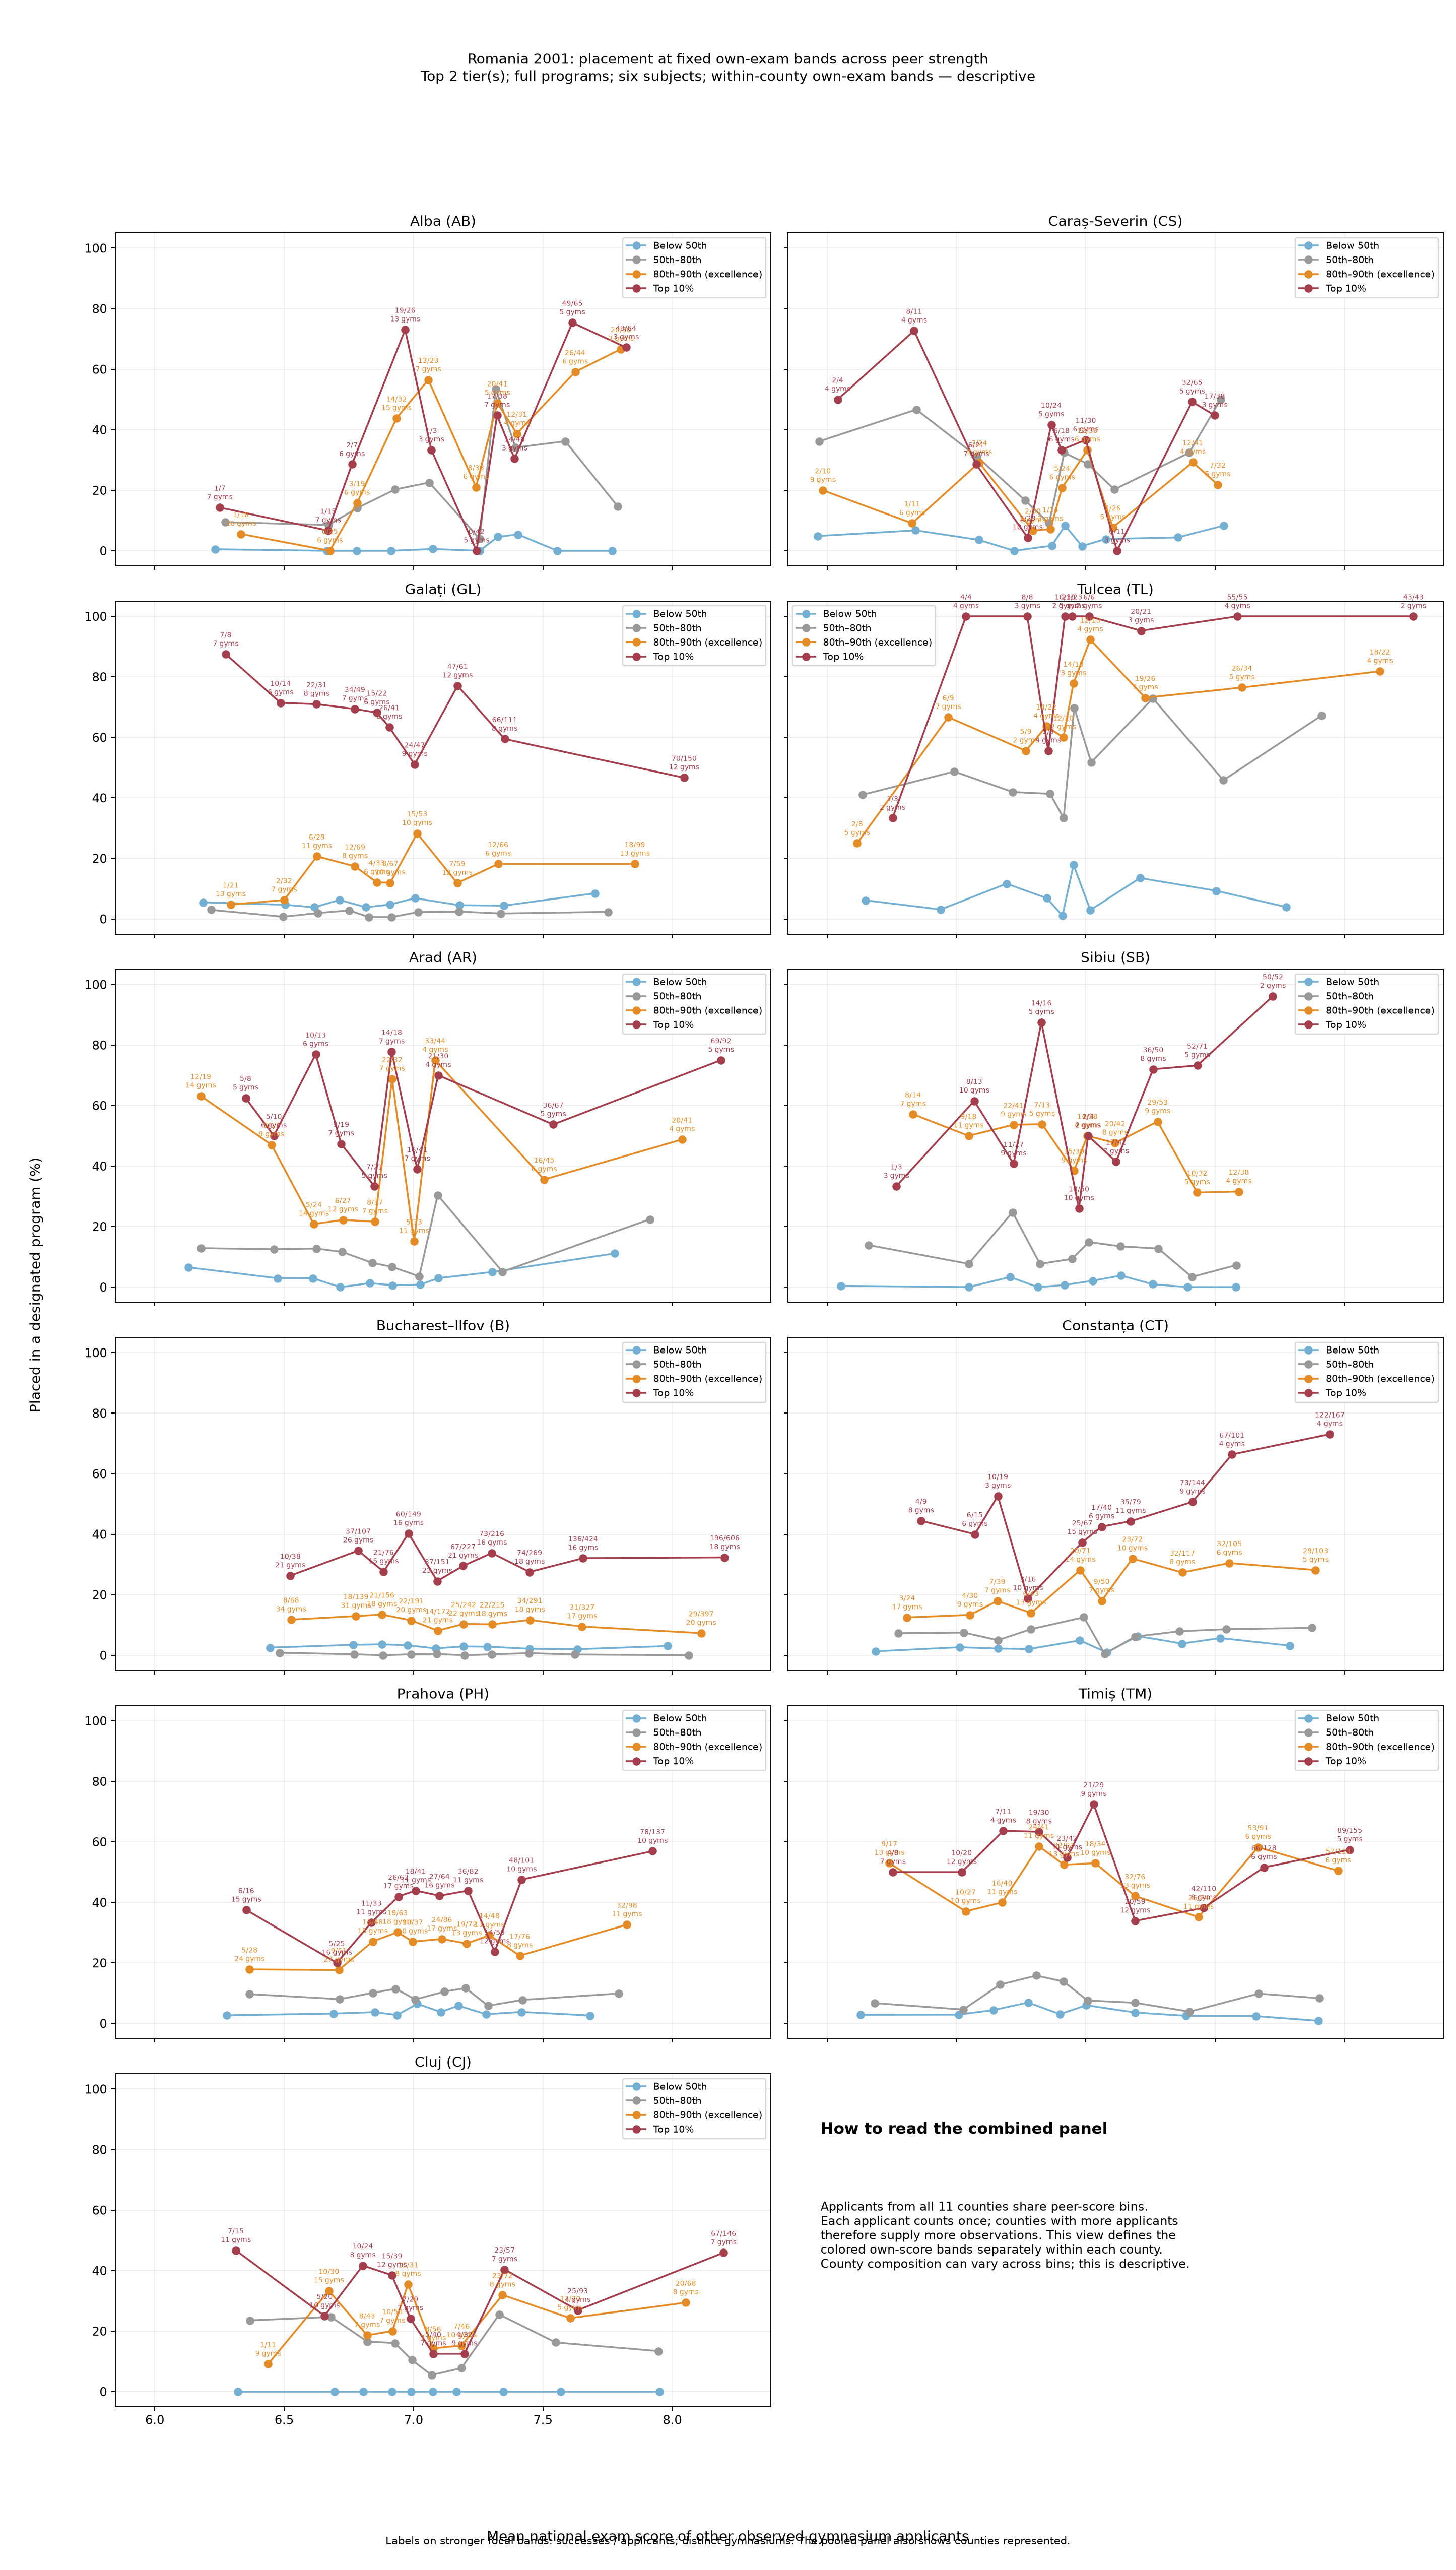

Displaying: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis/outputs/romania_2001_all_scraped_counties_descriptive_pilot/run_20261009T130311-0400/conditional_combined_bands_top2.png


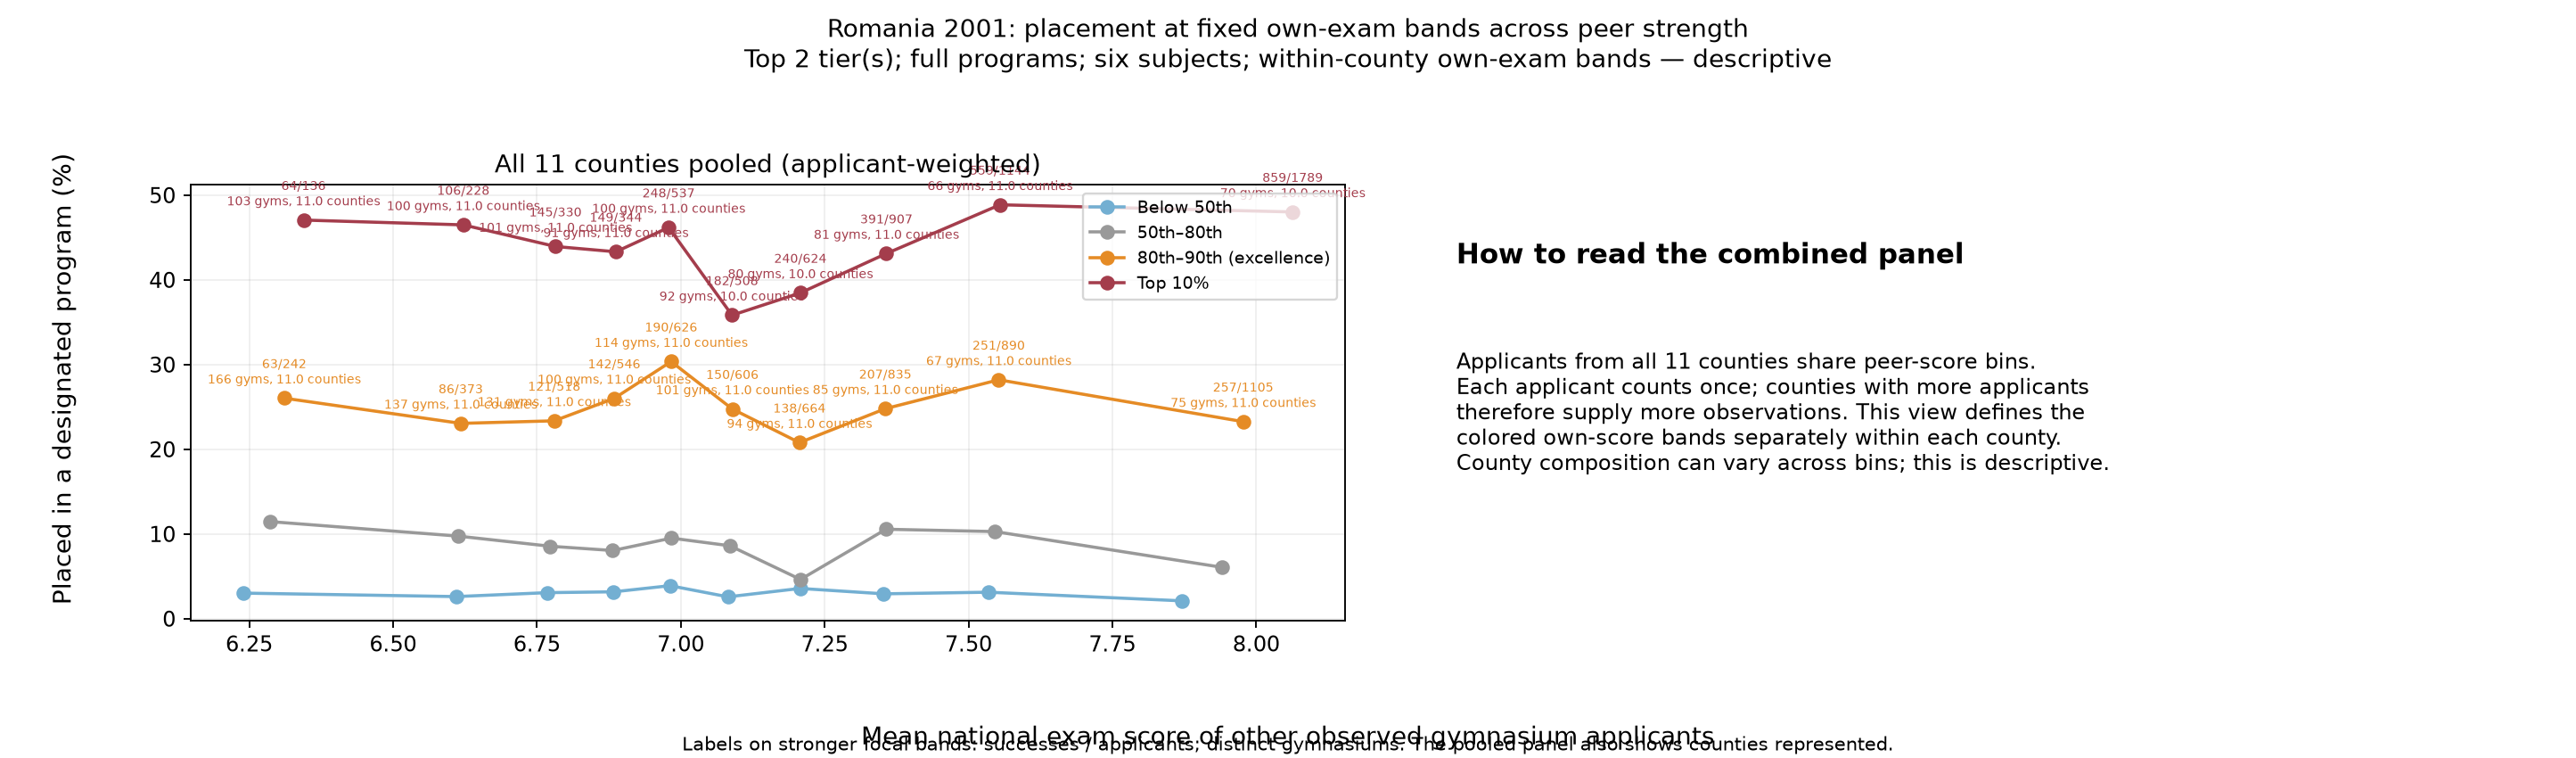

Displaying: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/education_analysis/outputs/romania_2001_all_scraped_counties_descriptive_pilot/run_20261009T130311-0400/conditional_combined_equal_county_bands_top2.png


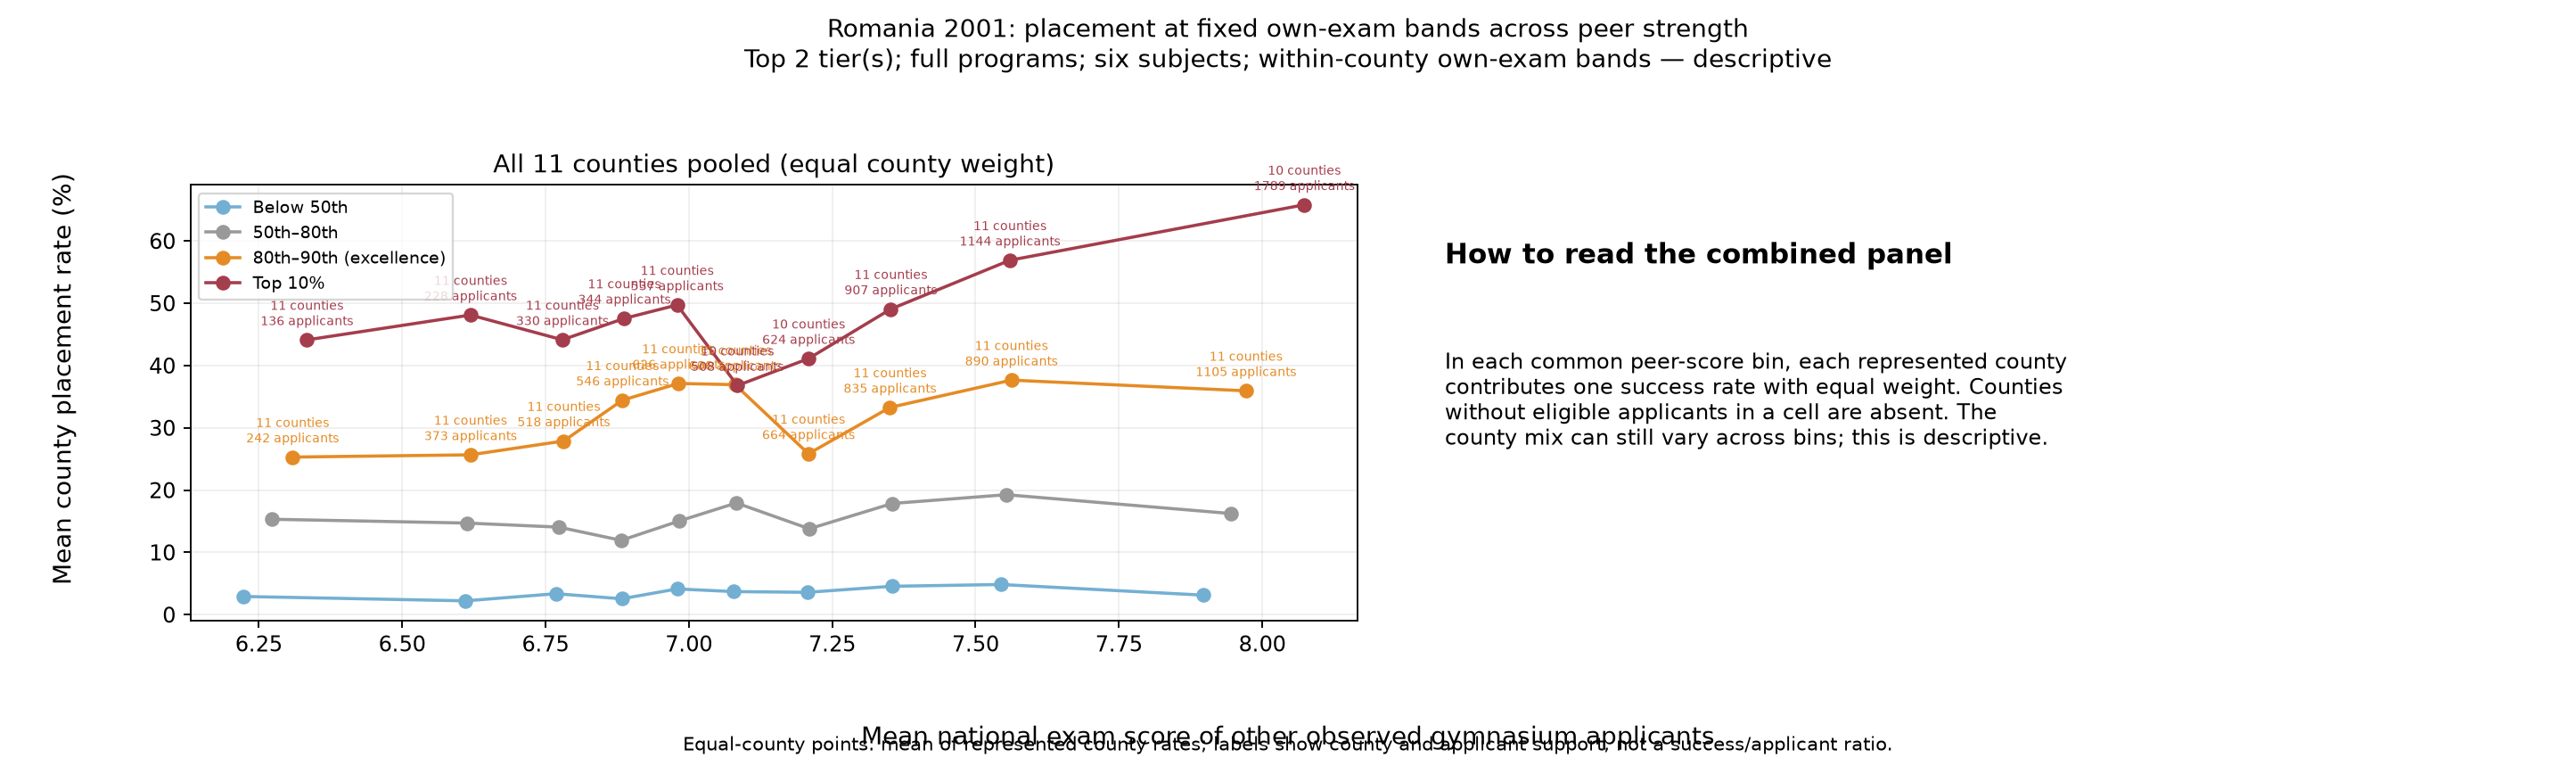

In [9]:
# CELL 4 — OWN-SCORE BANDS AND FIGURE DISPLAY
from dataclasses import asdict, replace
import json

TIER_TO_VIEW = 2
FIGURE_TO_VIEW = "all_counties"  # quantile plot, then EW plot below
# FIGURE_TO_VIEW choices — all use the cutoff tier chosen by TIER_TO_VIEW:
#
# "gymnasium_mean": Two combined line plots, quantile first and equal-width
#     second. Each gymnasium enters one bin based on the mean exam score of all
#     its observed applicants. Colors use student-score bands defined across
#     all selected counties; each eligible student counts once in the outcome.
#
# "gymnasium_mean_quantile": Only the first plot above. The bins contain
#     roughly equal numbers of gymnasiums, though their score widths differ.
# "gymnasium_mean_equal_width": Only the second plot above. Every bin covers
#     the same range of gymnasium mean scores; empty ranges appear as gaps.
#
# "all_counties": Three line figures in sequence: separate county panels,
#     one combined applicant-weighted panel, then one combined equal-county
#     panel. Colors use student-score percentiles calculated WITHIN each
#     county. The horizontal measure is each student's leave-one-out mean
#     score of other applicants from the same gymnasium.
# "county_bands": The first two parts of that sequence in one multi-panel
#     figure: every county followed by the applicant-weighted combined panel.
# "equal_county_bands": Only the combined equal-county line panel. Each
#     represented county contributes one success rate per score-band/peer-bin
#     cell, regardless of its number of students; absent counties contribute
#     nothing. Its colors also use WITHIN-county student-score bands.
# "pooled_bands": County panels plus a combined applicant-weighted panel, but
#     the colored student-score bands use ONE common set of percentile cutoffs
#     across all selected counties. The horizontal measure remains each
#     student's leave-one-out gymnasium peer mean, not the full gym mean.
#
# "hero": Two bar charts (equal-width and quantile peer bins) for EACH county,
#     followed by both combined applicant-weighted bar charts. These bars
#     combine all student-score bands instead of showing colored band lines.
# "combined_hero": Only the two combined applicant-weighted HERO bar charts.
# "equal_county_hero": Only the two combined equal-county HERO bar charts;
#     each represented county's success rate has equal weight within a bin.
#

# Edit this tuple here if you want different colored student-score bands.
# It must contain three descending percentiles, e.g. (90, 75, 50).
CELL4_AI_PERCENTILE_CUTS = (90, 80, 50)
REBUILD_FOR_NEW_BANDS = True  # Change to True to recompute from saved pages.

# Compare ALL research settings with the saved run so an old PNG can never be
# displayed as though it used your newly chosen bands or denominator.
view_settings = replace(settings, ai_percentile_cuts=tuple(CELL4_AI_PERCENTILE_CUTS))
view_settings.validate()
requested_settings = json.loads(json.dumps(asdict(view_settings)))
saved_settings = None
if "run_folder" in globals() and (run_folder / "run_manifest.json").exists():
    saved_settings = json.loads(
        (run_folder / "run_manifest.json").read_text(encoding="utf-8")
    ).get("settings")

if saved_settings != requested_settings:
    if REBUILD_FOR_NEW_BANDS:
        print("Recomputing offline from saved sources with the Cell 4 band tuple...")
        run_folder, summary = new_county_pilot.run_pilot(view_settings, run=True)
        settings = view_settings  # Keep this kernel aligned with the new band tuple.
        print("New results saved:", run_folder)
    else:
        print(
            "The current saved plots use different settings (or no run is loaded). "
            "Set REBUILD_FOR_NEW_BANDS = True and rerun Cell 4 to create new plots. "
            "No analysis was run."
        )
else:
    print("Displaying the existing saved run; no recalculation needed.")

if "run_folder" in globals() and (
    (run_folder / "run_manifest.json").exists()
    and json.loads((run_folder / "run_manifest.json").read_text(encoding="utf-8")).get("settings")
    == requested_settings
):
    display(Markdown((run_folder / "report.md").read_text(encoding="utf-8")))
    if FIGURE_TO_VIEW == "gymnasium_mean":
        # Quantile first, then the otherwise identical equal-width figure.
        filenames = [
            f"combined_gymnasium_mean_top{TIER_TO_VIEW}.png",
            f"combined_gymnasium_mean_equal_width_top{TIER_TO_VIEW}.png",
        ]
    elif FIGURE_TO_VIEW == "all_counties":
        filenames = [
            f"conditional_county_only_bands_top{TIER_TO_VIEW}.png",
            f"conditional_combined_bands_top{TIER_TO_VIEW}.png",
            f"conditional_combined_equal_county_bands_top{TIER_TO_VIEW}.png",
        ]
    else:
        filenames = [{
            "hero": f"hero_top{TIER_TO_VIEW}.png",
            "combined_hero": f"hero_combined_top{TIER_TO_VIEW}.png",
            "equal_county_hero": f"hero_combined_equal_county_top{TIER_TO_VIEW}.png",
            "equal_county_bands": f"conditional_combined_equal_county_bands_top{TIER_TO_VIEW}.png",
            "county_bands": f"conditional_county_bands_top{TIER_TO_VIEW}.png",
            "pooled_bands": f"conditional_pooled_bands_top{TIER_TO_VIEW}.png",
            "gymnasium_mean_quantile": f"combined_gymnasium_mean_top{TIER_TO_VIEW}.png",
            "gymnasium_mean_equal_width": f"combined_gymnasium_mean_equal_width_top{TIER_TO_VIEW}.png",
        }[FIGURE_TO_VIEW]]
    for filename in filenames:
        figure_path = run_folder / filename
        if not figure_path.exists():
            print("This older run lacks the requested figure. Set REBUILD_FOR_NEW_BANDS = True:", figure_path)
        else:
            print("Displaying:", figure_path)
            display(Image(filename=str(figure_path)))